# The Farm-Household Model: Autarky, Markets, and Separation

**ECO 701: Microeconomic Theory**  
*Companion Computational Notebook*

In standard introductory microeconomics, consumption theory (utility maximization by households) and production theory (profit maximization by firms) are taught in isolation. However, in developing economies and agricultural settings, the fundamental economic unit is often the **farm household**—an entity that acts simultaneously as a **producing firm** and a **consuming household**.

This notebook explores:
1. **The Autarkic (Chayanovian) Benchmark:** A self-sufficient household without labor or commodity markets, where production and consumption decisions are inextricably linked (**non-separable**).
2. **The Separable Market Model (Singh, Squire, & Strauss 1986; Benjamin 1992):** When competitive markets for labor and output exist, the household's decision separates into a two-stage recursive problem.
3. **Labor Regimes:** Visualizing net labor exporters, net labor importers, and landless laborers.
4. **Comparative Statics & The Inverse Relationship:** How market failures explain the famous inverse farm-size productivity relationship.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Consistent styling for matplotlib
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#f1f5f9'


---

## 1. Model Setup: Technology and Preferences

Consider a farm household endowed with:
- Fixed land holding $\bar{T}$
- Total time endowment $\bar{L}$ (which can be allocated between on-farm/off-farm labor $L$ and leisure $l = \bar{L} - L$)

### Production Technology
The farm produces agricultural output (food) $Q$ using land $\bar{T}$ and labor $L$ via a Cobb-Douglas production function:
$$Q = F(\bar{T}, L) = A \bar{T}^{1-\alpha} L^\alpha \quad (0 < \alpha < 1)$$

Marginal product of labor:
$$\text{MP}_L(L) = \frac{\partial F}{\partial L} = \alpha A \bar{T}^{1-\alpha} L^{\alpha-1} = \frac{\alpha Q}{L}$$

### Household Preferences
The household derives utility from consumption of food $c$ and leisure $l$:
$$U(c, l) = c^\beta l^{1-\beta} \quad (0 < \beta < 1)$$

Marginal rate of substitution (MRS) between leisure and consumption:
$$\text{MRS}(c, l) = \frac{\partial U / \partial l}{\partial U / \partial c} = \frac{(1-\beta) c}{\beta l}$$


---

## 2. Part 1: The Autarkic (Chayanovian) Household

In an isolated village without labor or output markets (the **Robinson Crusoe / A.V. Chayanov** case), the household must consume exactly what it produces and supply all its own labor:
$$c = F(\bar{T}, L) \quad \text{and} \quad L = \bar{L} - l$$

The household solves:
$$\max_{l} U\left(F(\bar{T}, \bar{L}-l),\, l\right)$$

### First-Order Condition
Equating the marginal rate of substitution to the marginal product of labor:
$$\text{MRS}(c, l) = \text{MP}_L(L) \implies \frac{(1-\beta) F(\bar{T}, \bar{L}-l)}{\beta l} = \alpha \frac{F(\bar{T}, \bar{L}-l)}{\bar{L}-l}$$

Canceling $F(\bar{T}, L)$ from both sides yields the closed-form autarkic allocation:
$$l^*_{\text{aut}} = \frac{1-\beta}{1 - \beta(1-\alpha)} \bar{L}, \qquad L^*_{\text{aut}} = \bar{L} - l^*_{\text{aut}} = \frac{\alpha \beta}{1 - \beta(1-\alpha)} \bar{L}$$

The internal **shadow wage** $w^*$ is the marginal product evaluated at $L^*_{\text{aut}}$:
$$w^* = \text{MP}_L(L^*_{\text{aut}}) = \alpha A \bar{T}^{1-\alpha} (L^*_{\text{aut}})^{\alpha-1}$$

> **Key Takeaway (Non-Separability):** Under autarky, production $L^*$ depends directly on consumer preferences ($\beta$) and time endowment ($\bar{L}$). Furthermore, labor intensity $L^*/\bar{T}$ decreases as farm size $\bar{T}$ increases, generating the empirical **Inverse Farm Size-Productivity Relationship**.


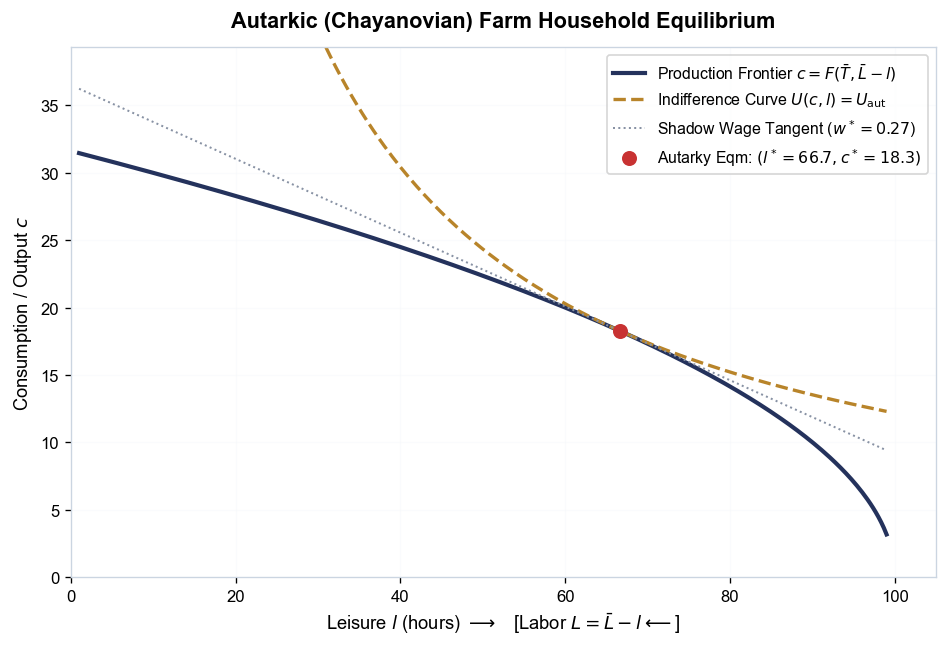

In [2]:
# Model parameters
A = 1.0
alpha = 0.5   # Labor share in production
beta = 0.5    # Food weight in utility
Lbar = 100.0  # Total time endowment
Tbar = 10.0   # Land endowment

# Autarky analytical solution
l_aut = ((1 - beta) / (1 - beta * (1 - alpha))) * Lbar
L_aut = Lbar - l_aut
c_aut = A * (Tbar**(1 - alpha)) * (L_aut**alpha)
w_shadow = alpha * A * (Tbar**(1 - alpha)) * (L_aut**(alpha - 1))
u_aut = (c_aut**beta) * (l_aut**(1 - beta))

# Grid for plotting
l_grid = np.linspace(1, Lbar - 1, 300)
L_grid = Lbar - l_grid
c_prod = A * (Tbar**(1 - alpha)) * (L_grid**alpha)
c_indiff = (u_aut / (l_grid**(1 - beta)))**(1 / beta)

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=120)

# Plot production possibility curve and indifference curve
ax.plot(l_grid, c_prod, label=r'Production Frontier $c = F(\bar{T}, \bar{L}-l)$', color='#24325c', lw=2.5)
ax.plot(l_grid, c_indiff, label=r'Indifference Curve $U(c,l) = U_{\mathrm{aut}}$', color='#b8842a', lw=2, ls='--')

# Tangent line with slope = -w*
c_tangent = c_aut - w_shadow * (l_grid - l_aut)
mask = (c_tangent >= 0) & (c_tangent <= c_prod.max() * 1.3)
ax.plot(l_grid[mask], c_tangent[mask], label=f'Shadow Wage Tangent ($w^*={w_shadow:.2f}$)', color='#8892a4', lw=1.2, ls=':')

# Point of tangency
ax.plot(l_aut, c_aut, 'o', color='#c83232', markersize=8, zorder=5, label=f'Autarky Eqm: $(l^*={l_aut:.1f}, c^*={c_aut:.1f})$')

ax.set_xlim(0, Lbar * 1.05)
ax.set_ylim(0, c_prod.max() * 1.25)
ax.set_xlabel(r'Leisure $l$ (hours) $\longrightarrow$   [Labor $L = \bar{L}-l \longleftarrow$]', fontsize=11)
ax.set_ylabel('Consumption / Output $c$', fontsize=11)
ax.set_title('Autarkic (Chayanovian) Farm Household Equilibrium', fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='upper right', frameon=True, fontsize=9.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---

## 3. Part 2: The Separable Farm Household with Markets

Now suppose competitive markets exist for both labor (market wage $w$) and agricultural output (price $p$, normalized to $p = 1$). 

The household can now:
- Hire in farm labor ($L > \bar{L}-l$) or hire out family labor to off-farm employment ($L < \bar{L}-l$).
- Buy or sell agricultural output on the market.

### The Two-Stage Separation Property
The household's optimization problem decomposes into two independent stages:

#### Stage 1: Profit Maximization (Firm Problem)
The farm operates as a pure profit-maximizing enterprise, choosing total labor demand $L^*$ on the farm:
$$\max_{L} \Pi = F(\bar{T}, L) - w L \implies \text{MP}_L(L^*) = w$$

Solving for optimal farm labor demand:
$$\mathbf{L^*(w, \bar{T}) = \left(\frac{\alpha A}{w}\right)^{\frac{1}{1-\alpha}} \bar{T}}$$

Farm profit (land rent):
$$\mathbf{\Pi^*(w, \bar{T}) = F(\bar{T}, L^*) - w L^* = (1-\alpha) Q^*}$$

> **The Separation Property:** Labor demand $L^*$ and farm output $Q^*$ depend **only** on technology $A$, land $\bar{T}$, and the market wage $w$. They are completely **independent of household preferences $\beta$ or family size $\bar{L}$**.

#### Stage 2: Utility Maximization (Household Problem)
The household receives full income $\bar{Y}$ comprising farm profits plus the market value of its time endowment:
$$\bar{Y} = \Pi^*(w, \bar{T}) + w \bar{L}$$

The household maximizes utility subject to the full-income budget constraint $c + w l \le \bar{Y}$:
$$\max_{c, l} U(c, l) \quad \text{s.t.} \quad c + w l \le \bar{Y}$$

Optimal consumption and leisure demand:
$$\mathbf{c^* = \beta \bar{Y}}, \qquad \mathbf{l^* = \frac{(1-\beta) \bar{Y}}{w}}$$

Family labor supply: $L^s = \bar{L} - l^*$.


---

## 4. Part 3: Labor Market Regimes

Depending on its land endowment $\bar{T}$, family size $\bar{L}$, and preferences, the household falls into one of three distinct labor market regimes:

1. **Net Labor Exporter ($L^* < L^s$):** Small land endowment relative to family labor. The household works on its own farm and sells surplus labor on the wage market.
2. **Net Labor Importer ($L^* > L^s$):** Large land endowment relative to family labor. The household's farm labor demand exceeds family supply, hiring in hired hands.
3. **Landless Household ($\bar{T} = 0$):** Zero farm profits ($\Pi^* = 0$). Operates as a pure neoclassical wage worker.


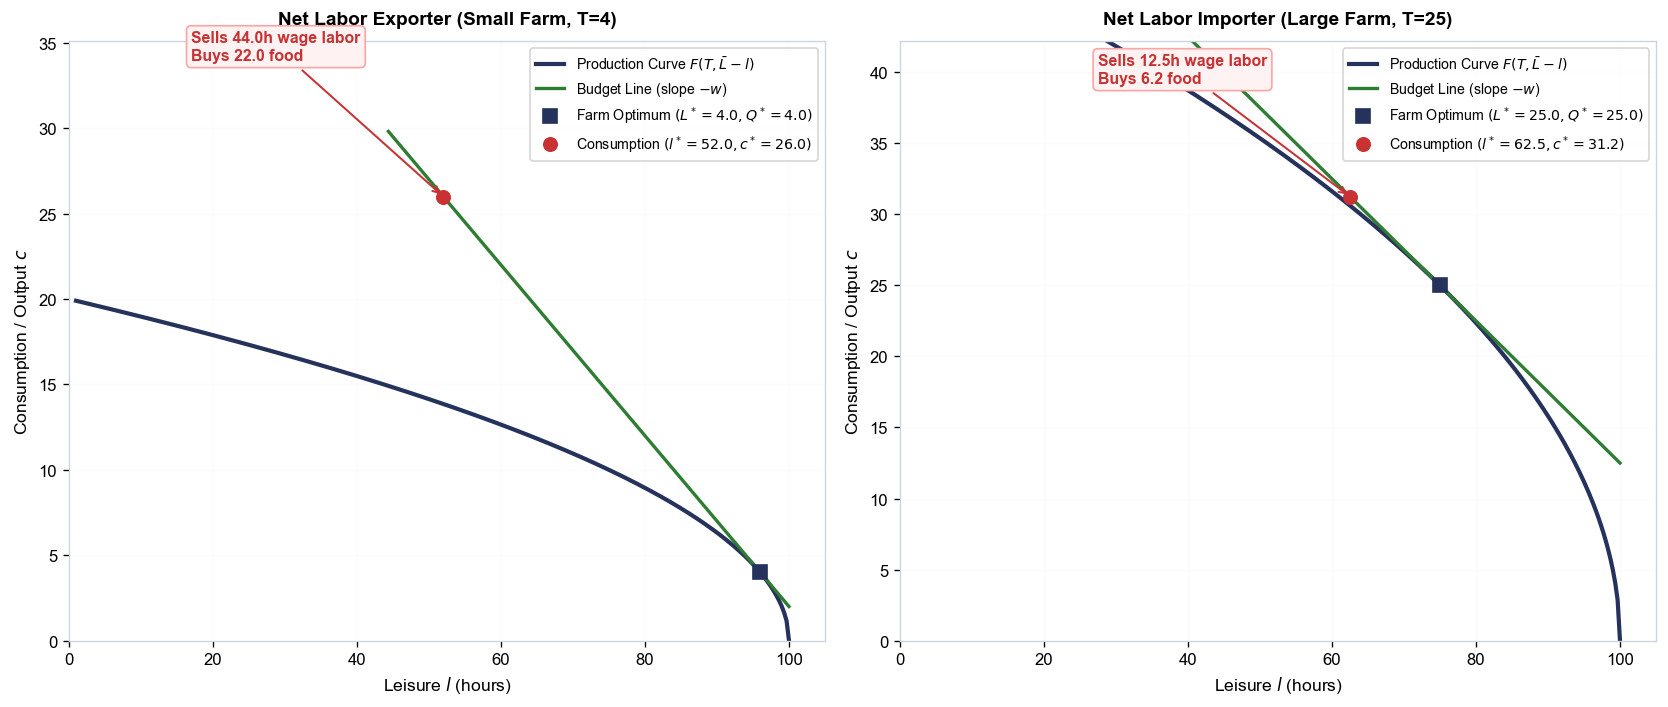

In [3]:
def solve_farm_household(w, Tbar, Lbar, alpha=0.5, beta=0.5, A=1.0):
    # Stage 1: Production
    L_opt = ((alpha * A * (Tbar**(1 - alpha))) / w)**(1 / (1 - alpha))
    Q_opt = A * (Tbar**(1 - alpha)) * (L_opt**alpha)
    profit = Q_opt - w * L_opt
    
    # Stage 2: Consumption
    Y_full = profit + w * Lbar
    c_opt = beta * Y_full
    l_opt = ((1 - beta) * Y_full) / w
    L_supply = Lbar - l_opt
    net_labor_hired = L_opt - L_supply  # >0 hired in, <0 sold out
    net_food_marketed = Q_opt - c_opt   # >0 sold, <0 bought
    
    return {
        'L_opt': L_opt, 'Q_opt': Q_opt, 'profit': profit, 'Y_full': Y_full,
        'c_opt': c_opt, 'l_opt': l_opt, 'L_supply': L_supply,
        'net_labor_hired': net_labor_hired, 'net_food_marketed': net_food_marketed
    }

w_market = 0.5
hh_exporter = solve_farm_household(w=w_market, Tbar=4.0, Lbar=100.0)
hh_importer = solve_farm_household(w=w_market, Tbar=25.0, Lbar=100.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=120)

for ax, res, title in zip([ax1, ax2], [hh_exporter, hh_importer], 
                          ['Net Labor Exporter (Small Farm, T=4)', 'Net Labor Importer (Large Farm, T=25)']):
    l_grid = np.linspace(1, 100, 300)
    L_grid = 100 - l_grid
    c_prod = A * ((4.0 if 'Small' in title else 25.0)**(1 - alpha)) * (L_grid**alpha)
    
    # Production curve & Budget line
    ax.plot(l_grid, c_prod, label=r'Production Curve $F(T, \bar{L}-l)$', color='#24325c', lw=2.5)
    
    # Full income budget line: c = Y_full - w*l
    c_budget = res['Y_full'] - w_market * l_grid
    mask = (c_budget >= 0) & (c_budget <= c_prod.max() * 1.5)
    ax.plot(l_grid[mask], c_budget[mask], label=r'Budget Line (slope $-w$)', color='#2e7d32', lw=2)
    
    # Production choice L*
    l_prod_pt = 100 - res['L_opt']
    ax.plot(l_prod_pt, res['Q_opt'], 's', color='#24325c', markersize=8, zorder=5, 
            label=f'Farm Optimum $(L^*={res["L_opt"]:.1f}, Q^*={res["Q_opt"]:.1f})$')
    
    # Consumption choice (l*, c*)
    ax.plot(res['l_opt'], res['c_opt'], 'o', color='#c83232', markersize=8, zorder=5,
            label=f'Consumption $(l^*={res["l_opt"]:.1f}, c^*={res["c_opt"]:.1f})$')
    
    # Label net transactions
    if res['net_labor_hired'] < 0:
        ax.annotate(f"Sells {-res['net_labor_hired']:.1f}h wage labor\nBuys {-res['net_food_marketed']:.1f} food",
                    xy=(res['l_opt'], res['c_opt']), xytext=(res['l_opt']-35, res['c_opt']+8),
                    arrowprops=dict(arrowstyle="->", color="#c83232", lw=1.2),
                    fontsize=9.5, fontweight='bold', color='#c83232',
                    bbox=dict(boxstyle="round,pad=0.3", fc="#fef2f2", ec="#fca5a5"))
    else:
        ax.annotate(f"Hires {res['net_labor_hired']:.1f}h labor\nSells {res['net_food_marketed']:.1f} food surplus",
                    xy=(res['l_opt'], res['c_opt']), xytext=(res['l_opt']-45, res['c_opt']+12),
                    arrowprops=dict(arrowstyle="->", color="#2e7d32", lw=1.2),
                    fontsize=9.5, fontweight='bold', color='#2e7d32',
                    bbox=dict(boxstyle="round,pad=0.3", fc="#f0fdf4", ec="#86efac"))
        
    ax.set_xlim(0, 105)
    ax.set_ylim(0, max(res['Q_opt'], res['c_opt']) * 1.35)
    ax.set_xlabel(r'Leisure $l$ (hours)', fontsize=10.5)
    ax.set_ylabel(r'Consumption / Output $c$', fontsize=10.5)
    ax.set_title(title, fontsize=11.5, fontweight='bold', pad=10)
    ax.legend(loc='upper right', fontsize=8.5)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---

## 5. Part 4: Interactive Simulation & Comparative Statics

Use the interactive Plotly widget below to explore how changes in the **Market Wage ($w$)** affect farm labor demand, full income, and the household's labor market regime.


In [4]:
import plotly.graph_objects as go
import numpy as np

w_vals = [0.25, 0.50, 0.75, 1.00, 1.25]
Lbar = 100.0
Tbar_fixed = 10.0
alpha = 0.5
beta = 0.5
A = 1.0

def make_plotly_traces(w):
    res = solve_farm_household(w, Tbar=Tbar_fixed, Lbar=Lbar, alpha=alpha, beta=beta, A=A)
    l_g = np.linspace(1, 99, 150)
    L_g = Lbar - l_g
    c_p = A * (Tbar_fixed**(1 - alpha)) * (L_g**alpha)
    c_b = res['Y_full'] - w * l_g
    
    # Production curve
    t_prod = go.Scatter(x=l_g, y=c_p, mode='lines', name='Production Curve', line=dict(color='#24325c', width=3))
    # Budget line
    t_bud = go.Scatter(x=l_g, y=c_b, mode='lines', name=f'Budget Line (w={w:.2f})', line=dict(color='#2e7d32', width=2, dash='dash'))
    # Farm production point
    t_fpt = go.Scatter(x=[Lbar - res['L_opt']], y=[res['Q_opt']], mode='markers+text', text=['Farm Opt (L*)'],
                       textposition='top right', marker=dict(size=10, color='#24325c', symbol='square'), name='Farm Optimum')
    # Household consumption point
    t_cpt = go.Scatter(x=[res['l_opt']], y=[res['c_opt']], mode='markers+text', text=['Consumption (l*, c*)'],
                       textposition='bottom left', marker=dict(size=11, color='#c83232'), name='Consumption Optimum')
    return [t_prod, t_bud, t_fpt, t_cpt]

fig_interactive = go.Figure(data=make_plotly_traces(0.50))

frames = [
    go.Frame(data=make_plotly_traces(w), name=f'{w:.2f}')
    for w in w_vals
]
fig_interactive.frames = frames

steps = [
    dict(method='animate', args=[[f'{w:.2f}'], dict(mode='immediate', frame=dict(duration=150, redraw=True))], label=f'w = {w:.2f}')
    for w in w_vals
]

sliders = [dict(
    active=1,
    currentvalue=dict(prefix='Market Real Wage: ', visible=True, xanchor='center', font=dict(size=12, color='#2e7d32')),
    pad=dict(t=25, b=5), len=0.9, x=0.05, steps=steps
)]

fig_interactive.update_layout(
    title='Interactive Farm-Household Model: Varying the Market Wage',
    xaxis=dict(title='Leisure l (hours)', range=[0, 105], showgrid=True, gridcolor='#f1f5f9'),
    yaxis=dict(title='Consumption / Output c', range=[0, 45], showgrid=True, gridcolor='#f1f5f9'),
    height=500, width=720,
    sliders=sliders,
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)
fig_interactive


---

## 6. Summary of Key Theoretical Insights

| Dimension | Autarkic (Chayanovian) Model | Separable Market Model |
| :--- | :--- | :--- |
| **Labor Demand ($L^*$)** | Depends on family size $\bar{L}$ and preferences $\beta$. | Depends strictly on $(T, w, p)$; independent of $\bar{L}, \beta$. |
| **Land Allocation** | Small farms cultivate land more intensively ($L^*/T \uparrow$). | All farms equate $\text{MP}_L = w/p$; identical intensity $L^*/T$. |
| **Inverse Relationship (IR)** | **Present:** Diminishing returns + fixed family labor supply. | **Absent:** Incomplete/missing markets are required to generate the IR. |
| **Welfare Impact of Prices** | Ambiguous (depends on shadow price). | **Deaton (1989):** $\Delta \text{Welfare} \approx (Q^* - c^*) \Delta p$. Net producers gain; net consumers lose. |
